# Proyecto Centinela - Fase 1: Centinela de la Papa
### Redes Neuronales - Deep Learning (EA-N-F-004) - Maestria en Ciencia de Datos, USTA
Integrantes: Juan Guillermo Montano Junca y Jair Andres Valderrama Cano - version v1

Linea base con un MLP sobre la imagen aplanada a tabla (rasgos de color y textura por hoja) para predecir **hoja enferma: si/no** (tizon temprano o tardio frente a sana). Datos: Irish Potato Imagery Dataset (Zenodo, CC BY 4.0). El clima de NASA POWER entra en la Fase 2.

Estructura: 0 entorno - 1 datos - 2 EDA y particion - 3 arquitectura y capacidad - 4 bucle - 5 diagnostico y lineas base - 6 regularizacion - 7 umbral por costo, prueba, errores y etica - 8 autoevaluacion - anexos.

## 0. Preparacion del entorno

In [1]:
import io, zipfile, os, random, urllib.request
import numpy as np, pandas as pd
import torch, torch.nn as nn
import matplotlib.pyplot as plt
from PIL import Image, ImageFile
from collections import Counter
import json
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, GroupShuffleSplit
ImageFile.LOAD_TRUNCATED_IMAGES = True      # fotos de celular a veces vienen truncadas
from sklearn.metrics import (confusion_matrix, classification_report, roc_auc_score,
                             precision_recall_curve, recall_score, precision_score, f1_score)

SEMILLA = 42
random.seed(SEMILLA); np.random.seed(SEMILLA); torch.manual_seed(SEMILLA)   # semilla en las tres librerias
print("torch", torch.__version__, "| GPU:", torch.cuda.is_available())

torch 2.15.0+cu132 | GPU: False


## 1. El problema y los datos
Cada foto de hoja se resume en rasgos tabulares de color y textura: es la "version aplanada" de la imagen. En la Fase 2 se reemplaza por una CNN.

Todo corre en la nube de Colab, sin Drive: los zips se bajan al disco temporal (`/content`), se procesan de a uno y se borran. Solo queda `rasgos_papa.csv` (pocos MB). `POR_CLASE = 1500` para iterar; `None` para todo.

In [2]:
ZIPS = {   # clase -> (nombre del zip, URL de Zenodo, etiqueta 0=sana 1=enferma)
    "sana":     ("healthy.zip",  "https://zenodo.org/records/8286529/files/healthy.zip?download=1",  0),
    "temprano": ("earlyblt.zip", "https://zenodo.org/records/8286529/files/earlyblt.zip?download=1", 1),
    "tardio":   ("lateblt.zip",  "https://zenodo.org/records/8286529/files/lateblt.zip?download=1",  1),
}
POR_CLASE   = 1500
LADO        = 128
CSV         = "rasgos_papa.csv"
BORRAR_ZIPS = True

# Rasgos ya extraidos (con notebooks/extraer_rasgos.py) y publicados en el repositorio
REPO_RAW = "https://raw.githubusercontent.com/N3UR0SlS/Centinela-Papa/main/datos_derivados/"

In [3]:
# 1) Intenta bajar los rasgos ya extraidos desde GitHub (segundos)
for archivo in [CSV, "auditoria_extraccion.json"]:
    if not os.path.exists(archivo):
        try:
            urllib.request.urlretrieve(REPO_RAW + archivo, archivo); print("Bajado de GitHub:", archivo)
        except Exception as e:
            print("No se pudo bajar", archivo, "de GitHub:", type(e).__name__)

# 2) Solo si sigue faltando el CSV, baja los zips de Zenodo (lento) con barra de progreso
if not os.path.exists(CSV):
    for clase, (nombre, url, _) in ZIPS.items():
        if not os.path.exists(nombre):
            !wget -c -q --show-progress -O {nombre} "{url}"

In [4]:
def rasgos_imagen(img, lado=LADO):
    """Resume una hoja en rasgos de color y textura."""
    a = np.asarray(img.convert("RGB").resize((lado, lado)), dtype=np.float32)
    R, G, B = a[:, :, 0], a[:, :, 1], a[:, :, 2]
    gris = 0.299 * R + 0.587 * G + 0.114 * B
    exg = 2 * G - R - B                              # exceso de verde: hoja sana = mas verde
    necrosis = float(np.mean((R > G) & (R > B)))     # fraccion parduzca/rojiza: lesiones
    gx, gy = np.gradient(gris)
    textura = float(np.std(np.sqrt(gx ** 2 + gy ** 2)))
    return [R.mean(), G.mean(), B.mean(), R.std(), G.std(), B.std(),
            float(exg.mean()), necrosis, float(gris.mean()), textura]

COLUMNAS = ["R_media","G_media","B_media","R_std","G_std","B_std",
            "exg_media","necrosis_frac","brillo_media","textura"]

def descargar(nombre, url):
    if not os.path.exists(nombre):
        print("Descargando", nombre, "..."); urllib.request.urlretrieve(url, nombre)

def es_imagen_real(n):
    base = n.split("/")[-1]
    return (n.lower().endswith((".jpg", ".jpeg", ".png"))
            and "__MACOSX" not in n and not base.startswith("._"))

def meta_exif(img):
    """Fecha de la toma y si la foto trae GPS (solo si/no; nunca se guardan coordenadas)."""
    try:
        ex = img._getexif() or {}
    except Exception:
        ex = {}
    f = ex.get(36867)                                  # 36867 = DateTimeOriginal
    fecha = f.split(" ")[0].replace(":", "-") if f else ""
    return fecha, int(34853 in ex)                     # 34853 = GPSInfo

def construir_tabla():
    filas, y, clases, fechas, gps, stats = [], [], [], [], [], {}
    for clase, (nombre, url, etiqueta) in ZIPS.items():
        descargar(nombre, url)
        errores = Counter()
        with zipfile.ZipFile(nombre) as z:
            todos = [n for n in z.namelist() if n.lower().endswith((".jpg", ".jpeg", ".png"))]
            nombres = [n for n in todos if es_imagen_real(n)]
            basura = len(todos) - len(nombres)
            random.Random(SEMILLA).shuffle(nombres)
            if POR_CLASE: nombres = nombres[:POR_CLASE]
            ok = 0
            for n in nombres:
                try:
                    img = Image.open(io.BytesIO(z.read(n)))
                    f, tg = meta_exif(img)
                    filas.append(rasgos_imagen(img))
                    y.append(etiqueta); clases.append(clase); fechas.append(f); gps.append(tg); ok += 1
                except Exception as e:
                    errores[type(e).__name__] += 1       # se registra, no se esconde
        stats[clase] = {"entradas_jpg": len(todos), "basura_no_imagen": basura,
                        "intentadas": len(nombres), "ok": ok, "errores": dict(errores)}
        print(f"{clase}: {ok} de {len(nombres)} fotos OK | archivos que no son imagen: {basura} | errores: {dict(errores)}")
        if BORRAR_ZIPS: os.remove(nombre)
    json.dump(stats, open("auditoria_extraccion.json", "w"), indent=1)
    df = pd.DataFrame(filas, columns=COLUMNAS)
    df["enferma"] = y; df["clase"] = clases; df["fecha"] = fechas; df["tiene_gps"] = gps
    return df

if os.path.exists(CSV):
    df = pd.read_csv(CSV); print("CSV cargado:", df.shape)
else:
    df = construir_tabla(); df.to_csv(CSV, index=False); print("Tabla construida:", df.shape)
df.head()

CSV cargado: (58707, 14)


,R_media,G_media,B_media,R_std,G_std,B_std,exg_media,necrosis_frac,brillo_media,textura,enferma,clase,fecha,tiene_gps
0,137.860350,182.67413,42.684753,29.917854,23.492230,41.756420,184.803162,0.000000,153.316025,8.657027,0,sana,2023-01-16,0
1,127.467710,180.77942,66.618900,24.614220,20.890486,36.332256,167.472229,0.000000,151.824921,7.928347,0,sana,2023-01-25,0
2,138.014900,174.51941,59.609802,36.118458,33.358624,40.427532,151.414124,0.000488,150.504852,8.217663,0,sana,2023-01-25,0
3,137.075200,172.49402,80.487976,41.139423,35.203667,56.438190,127.424866,0.000793,151.415100,10.210745,0,sana,2023-01-16,1
4,127.000305,176.43884,86.477970,31.264582,23.140686,46.949840,139.399414,0.004517,151.401184,8.309587,0,sana,2023-01-12,1


## 2. Exploracion (EDA): cada hallazgo decide algo

In [5]:
print("Balance (enferma=1):"); print(df["enferma"].value_counts(normalize=True).round(3))
print("\nPor clase original:"); print(df["clase"].value_counts())
print("\nFaltantes por columna:", int(df[COLUMNAS].isna().sum().sum()))
con_fecha = df["fecha"].fillna("").astype(str).str.len() > 0
print("Fotos con fecha EXIF:", int(con_fecha.sum()), "de", len(df), f"({con_fecha.mean():.1%})",
      "| dias distintos:", df.loc[con_fecha, "fecha"].nunique())
df[COLUMNAS].describe().round(2)

Balance (enferma=1):
enferma
1    0.652
0    0.348
Name: proportion, dtype: float64

Por clase original:
clase
tardio      20499
sana        20438
temprano    17770
Name: count, dtype: int64

Faltantes por columna: 0
Fotos con fecha EXIF: 58698 de 58707 (100.0%) | dias distintos: 35


,R_media,G_media,B_media,R_std,G_std,B_std,exg_media,necrosis_frac,brillo_media,textura
count,58707.00,58707.00,58707.00,58707.00,58707.00,58707.00,58707.00,58707.00,58707.00,58707.00
mean,134.40,170.35,58.62,34.30,34.80,38.34,147.68,0.09,146.87,9.25
std,12.45,12.49,22.03,8.39,9.96,9.39,29.83,0.11,10.76,2.30
min,0.87,91.96,4.20,1.21,9.84,5.30,1.38,0.00,59.65,1.71
25%,126.71,163.85,42.09,28.31,27.57,31.85,129.86,0.00,141.13,7.59
50%,134.48,172.24,57.91,33.78,34.44,37.37,150.26,0.06,147.96,8.94
75%,142.12,178.89,73.43,39.24,41.33,44.21,167.62,0.16,153.72,10.73
max,195.73,235.11,143.72,82.24,80.32,94.37,258.55,0.77,205.81,24.24


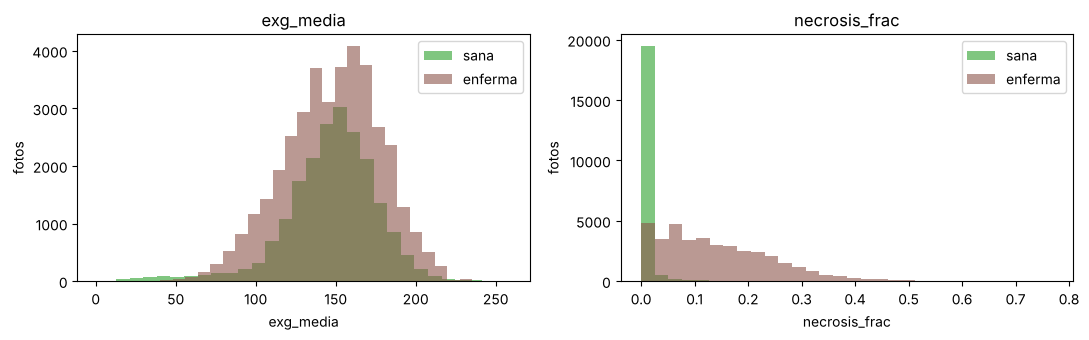

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
for v, eje in zip(["exg_media", "necrosis_frac"], ax):
    for et, col in [(0, "tab:green"), (1, "tab:brown")]:
        eje.hist(df[df.enferma == et][v], bins=30, alpha=0.6, color=col, label=("sana" if et == 0 else "enferma"))
    eje.set_title(v); eje.set_xlabel(v); eje.set_ylabel("fotos"); eje.legend()
plt.tight_layout(); plt.show()

### Atajos posibles: fecha y tipo de foto
La revision del EXIF mostro que las clases se fotografiaron en semanas distintas (sanas en enero, tizon temprano en febrero) y que la proporcion de fotos con GPS cambia mucho por clase (senal de celulares o configuraciones distintas). Si la fecha o el "tiene GPS" predicen solos la clase, el modelo podria aprender eso en vez de la enfermedad. Se mide con su AUC usados solos (sin modelo).

In [7]:
tiene_f = df["fecha"].fillna("").astype(str).str.len() > 0
dd = df[tiene_f].copy()
dd["dia_del_anio"] = pd.to_datetime(dd["fecha"]).dt.dayofyear
dd["dia_rel"] = (pd.to_datetime(dd["fecha"]) - pd.to_datetime(dd["fecha"]).min()).dt.days
print("Fechas por clase:")
print(dd.groupby("clase")["fecha"].agg(desde="min", hasta="max", dias_distintos="nunique"))
print("\nProporcion con GPS por clase:")
print(df.groupby("clase")["tiene_gps"].mean().round(3))
auc_fecha = roc_auc_score(dd["enferma"], dd["dia_rel"])
auc_gps = roc_auc_score(df["enferma"], df["tiene_gps"])
print(f"\nAUC de la fecha sola:      {max(auc_fecha, 1 - auc_fecha):.3f}")
print(f"AUC de 'tiene GPS' solo:   {max(auc_gps, 1 - auc_gps):.3f}")
print("(0.5 = no predice nada; cerca de 1 = atajo fuerte)")

Fechas por clase:
               desde       hasta  dias_distintos
clase                                           
sana      2022-11-22  2023-04-18              24
tardio    2023-01-09  2023-03-03              20
temprano  2023-01-08  2023-02-24              12

Proporcion con GPS por clase:
clase
sana        0.523
tardio      0.209
temprano    0.126
Name: tiene_gps, dtype: float64

AUC de la fecha sola:      0.998
AUC de 'tiene GPS' solo:   0.676
(0.5 = no predice nada; cerca de 1 = atajo fuerte)


Lectura (corrida del 2026-11-02, 58.707 fotos): **la fecha sola predice la clase con AUC 0.998**: las sanas se fotografiaron del 22 de noviembre al 18 de abril, pero casi todas en enero, y las enfermas entre el 8 de enero y el 3 de marzo, concentradas en febrero. **"Tiene GPS" solo da AUC 0.676** (52% de las sanas tiene GPS frente a 13% de temprano y 21% de tardio), senal de celulares o configuraciones distintas por clase. Ninguna de las dos entra al modelo, pero los rasgos de color pueden cargar diferencias de epoca, luz y camara; por eso la seccion 7 incluye una prueba que separa enfermedad de fecha. En la Fase 2 el clima por dia hereda este atajo, asi que su aporte en la ablacion solo es creible dentro de dias mixtos.

### Decisiones que deja el EDA
| Hallazgo | Decision |
|---|---|
| Desbalance (mayoria "enferma", ~65/35) | particion **estratificada**; metricas por clase, no solo exactitud |
| Escalas muy distintas (0-255 frente a 0-1) | **StandardScaler** ajustado solo con train (anti-fuga) |
| "Enferma" agrupa temprano y tardio | se guarda la clase original para medir errores **por subgrupo** |
| `necrosis_frac` separa bien las clases | se usa como **escalar crudo** de linea base |
| No hay finca, pero si fecha EXIF | prueba de robustez con particion agrupada por dia (seccion 7); el riesgo de casi duplicados se mide, no se supone |
| La clase depende de la fecha y del tipo de foto | la fecha y el GPS no entran al modelo; se reporta su AUC como atajo y se declara como limitacion |

In [8]:
idx = np.arange(len(df))
i_tr, i_tmp = train_test_split(idx, test_size=0.30, stratify=df["enferma"], random_state=SEMILLA)
i_va, i_te = train_test_split(i_tmp, test_size=0.50, stratify=df["enferma"].iloc[i_tmp], random_state=SEMILLA)

X = df[COLUMNAS].to_numpy("float32"); y = df["enferma"].to_numpy("float32")
escalador = StandardScaler().fit(X[i_tr])                     # SOLO train
X_tr, X_va, X_te = (escalador.transform(X[i]) for i in (i_tr, i_va, i_te))
y_tr, y_va, y_te = y[i_tr], y[i_va], y[i_te]
clase_te = df["clase"].to_numpy()[i_te]
print("train/val/test:", len(i_tr), len(i_va), len(i_te))

train/val/test: 41094 8806 8807


## 3. Arquitectura del MLP y capacidad
- **Salida en logit** (`nn.Linear(k, 1)`, sin sigmoide en el forward) con `BCEWithLogitsLoss` y etiqueta `(N, 1)` flotante. Poner `nn.Sigmoid()` en el modelo con esa perdida seria la doble sigmoide.
- **Por que ReLU en las ocultas:** la frontera sana/enferma no es una recta en el espacio de rasgos (por ejemplo, una hoja muy oscura puede tener poco verde sin estar enferma). Sin no linealidad, apilar capas equivale a una sola transformacion lineal y la red no podria doblar esa frontera. ReLU aporta esa no linealidad con un costo minimo y gradiente 1 en la zona activa.
- **Capacidad:** no se elige a ojo; se compara con medicion (celda siguiente).

In [9]:
class CentinelaMLP(nn.Module):
    def __init__(self, d_entrada, oculta1=16, oculta2=8, p_dropout=0.0):
        super().__init__()
        self.red = nn.Sequential(
            nn.Linear(d_entrada, oculta1), nn.ReLU(), nn.Dropout(p_dropout),   # oculta 1
            nn.Linear(oculta1, oculta2),  nn.ReLU(), nn.Dropout(p_dropout),   # oculta 2
            nn.Linear(oculta2, 1))                                            # salida: LOGIT
    def forward(self, x):
        return self.red(x)

## 4. Perdida, optimizador y bucle de entrenamiento explicito

In [10]:
def a_tensor(Xa, ya):
    return (torch.as_tensor(Xa, dtype=torch.float32),
            torch.as_tensor(ya, dtype=torch.float32).view(-1, 1))      # etiqueta (N,1) flotante

def entrenar(modelo, Xtr, ytr, Xva, yva, epocas=80, lr=1e-2, paciencia=15, weight_decay=0.0):
    Xtr, ytr = a_tensor(Xtr, ytr); Xva, yva = a_tensor(Xva, yva)
    criterio = nn.BCEWithLogitsLoss()
    optim = torch.optim.Adam(modelo.parameters(), lr=lr, weight_decay=weight_decay)
    hist = {"train": [], "val": []}
    mejor, mejor_ep, espera, mejor_estado = float("inf"), 0, 0, None
    for ep in range(1, epocas + 1):
        modelo.train()                      # Dropout activo
        logits = modelo(Xtr)                # 1 forward (logit)
        perdida = criterio(logits, ytr)     # 2 perdida
        optim.zero_grad()                   # 3 limpiar gradientes
        perdida.backward()                  # 4 backward
        optim.step()                        # 5 actualizar pesos
        modelo.eval()
        with torch.no_grad():
            pv = criterio(modelo(Xva), yva).item()
        hist["train"].append(perdida.item()); hist["val"].append(pv)
        if pv < mejor:
            mejor, mejor_ep, espera = pv, ep, 0
            mejor_estado = {k: v.clone() for k, v in modelo.state_dict().items()}   # guarda el mejor
        else:
            espera += 1
            if paciencia and espera >= paciencia:
                break
    modelo.load_state_dict(mejor_estado)    # restaura el minimo de validacion
    return hist, mejor_ep

def probas(modelo, Xa):
    modelo.eval()
    with torch.no_grad():
        return torch.sigmoid(modelo(torch.as_tensor(Xa, dtype=torch.float32))).numpy().ravel()

In [11]:
# Comparacion medida de capacidad: tres tamanos, misma semilla y mismos datos
filas = []
for h1, h2 in [(4, 2), (16, 8), (64, 32)]:
    torch.manual_seed(SEMILLA)
    m = CentinelaMLP(len(COLUMNAS), h1, h2)
    h, ep = entrenar(m, X_tr, y_tr, X_va, y_va)
    filas.append({"capas": f"{h1}-{h2}", "params": sum(p.numel() for p in m.parameters()),
                  "val_min": round(min(h["val"]), 4), "epoca_min": ep,
                  "AUC_val": round(roc_auc_score(y_va, probas(m, X_va)), 4)})
tabla_cap = pd.DataFrame(filas); tabla_cap

,capas,params,val_min,epoca_min,AUC_val
0,4-2,57,0.2529,80,0.9883
1,16-8,321,0.0816,80,0.9952
2,64-32,2817,0.0541,80,0.9973


Lectura: la red 64-32 logra la menor perdida de validacion (0.054 frente a 0.082 de la 16-8 y 0.253 de la 4-2) y el mayor AUC (0.997). La 4-2 queda corta: subajusta. Las tres alcanzan su minimo en la ultima epoca (80), asi que aun mejoraban; con lote completo hay una sola actualizacion por epoca y hace falta mas recorrido. Se elige 64-32 como capacidad de referencia, y la seccion 6 sube a 128-64 a proposito para intentar inducir el sobreajuste.

## 5. Diagnostico y lineas base comprometidas

In [12]:
def plot_curvas(hist, titulo):
    plt.figure(figsize=(6, 3.5))
    plt.plot(range(1, len(hist["train"]) + 1), hist["train"], label="entrenamiento")
    plt.plot(range(1, len(hist["val"]) + 1), hist["val"], label="validacion")
    plt.xlabel("epoca"); plt.ylabel("perdida BCE"); plt.title(titulo); plt.legend(); plt.show()

def plot_matriz(y_true, y_pred, titulo="Matriz de confusion (prueba)"):
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    plt.figure(figsize=(3.8, 3.3)); plt.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2):
            plt.text(j, i, cm[i, j], ha="center", va="center")
    plt.xticks([0, 1], ["sana", "enferma"]); plt.yticks([0, 1], ["sana", "enferma"])
    plt.xlabel("prediccion"); plt.ylabel("real"); plt.title(titulo); plt.show()

# Linea base 1: clase mayoritaria (todo "enferma")
pred_may = np.ones_like(y_te)
print("Clase mayoritaria  -> exactitud:", round(float((pred_may == y_te).mean()), 3),
      "| recall enferma:", round(recall_score(y_te, pred_may), 3),
      "| recall sana: 0.0")

# Linea base 2: escalar crudo (necrosis_frac sin escalar), umbral elegido en VALIDACION
nec = df["necrosis_frac"].to_numpy()
cands = np.quantile(nec[i_va], np.linspace(0.02, 0.98, 97))
u_nec = max(cands, key=lambda u: f1_score(y_va, (nec[i_va] >= u).astype(int)))
pred_nec = (nec[i_te] >= u_nec).astype(int)
print("Escalar crudo      -> umbral", round(float(u_nec), 4),
      "| exactitud:", round(float((pred_nec == y_te).mean()), 3),
      "| recall enferma:", round(recall_score(y_te, pred_nec), 3),
      "| AUC:", round(roc_auc_score(y_te, nec[i_te]), 3))

Clase mayoritaria  -> exactitud: 0.652 | recall enferma: 1.0 | recall sana: 0.0


Escalar crudo      -> umbral 0.0137 | exactitud: 0.906 | recall enferma: 0.91 | AUC: 0.967


## 6. Regularizacion: inducir y corregir el sobreajuste
Se induce el sobreajuste con una red grande, muchas epocas y sin freno, y se compara con tres intervenciones (Dropout, L2 y ambas), todas con la misma semilla. En cada corrida se nombra la epoca del minimo de validacion y la brecha entre entrenamiento y validacion.

In [13]:
corridas = {"sin regularizar": dict(p=0.0, wd=0.0),
            "Dropout 0.3":     dict(p=0.3, wd=0.0),
            "L2 1e-3":         dict(p=0.0, wd=1e-3),
            "Dropout + L2":    dict(p=0.3, wd=1e-3)}
res, modelos, hists = [], {}, {}
for nombre, c in corridas.items():
    torch.manual_seed(SEMILLA)
    m = CentinelaMLP(len(COLUMNAS), 128, 64, p_dropout=c["p"])
    h, ep = entrenar(m, X_tr, y_tr, X_va, y_va, epocas=200, paciencia=None, weight_decay=c["wd"])
    modelos[nombre], hists[nombre] = m, h
    res.append({"corrida": nombre, "epoca_min_val": ep, "val_min": round(min(h["val"]), 4),
                "val_final": round(h["val"][-1], 4),
                "brecha_en_min": round(h["val"][ep - 1] - h["train"][ep - 1], 4)})
tabla_reg = pd.DataFrame(res); tabla_reg

,corrida,epoca_min_val,val_min,val_final,brecha_en_min
0,sin regularizar,197,0.0447,0.0475,0.0158
1,Dropout 0.3,200,0.0427,0.0427,0.0069
2,L2 1e-3,196,0.0467,0.0473,0.0087
3,Dropout + L2,191,0.0484,0.0487,0.0013


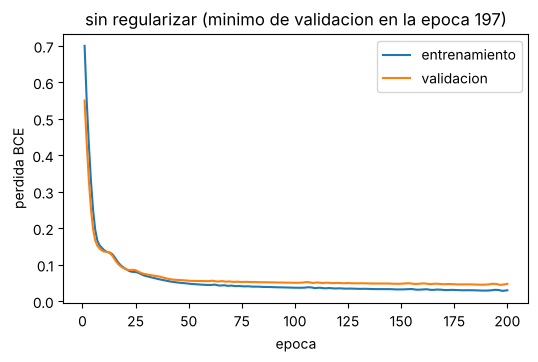

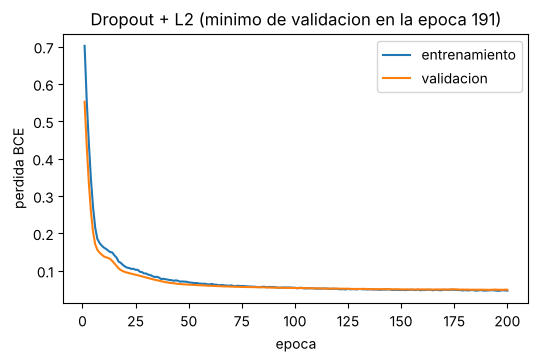

In [14]:
for nombre in ["sin regularizar", "Dropout + L2"]:
    plot_curvas(hists[nombre], f"{nombre} (minimo de validacion en la epoca {tabla_reg.set_index('corrida').loc[nombre,'epoca_min_val']})")

Lectura: **no aparecio sobreajuste** pese a subir la capacidad a 128-64 y entrenar 200 epocas sin parada temprana: en la corrida sin regularizar la validacion termina en 0.0475 con minimo de 0.0447 (casi igual) y la brecha entrenamiento-validacion en el minimo es 0.016. Con 41.000 fotos de entrenamiento y solo 10 rasgos, la red no tiene como memorizar. La regularizacion igual reduce la brecha (Dropout 0.007, Dropout + L2 0.001) y **Dropout 0.3 logra la menor perdida de validacion (0.0427)**, por eso es el modelo final, restaurado en su mejor epoca. Se documenta lo que se aumento (capacidad y epocas) y lo que se observo, como pide la rubrica.

## 7. Umbral por costo, evaluacion en prueba, errores y etica
**Costo de los errores para el cliente.** Un falso negativo (hoja enferma marcada sana) deja avanzar el tizon, que puede acabar con un lote en dias. Un falso positivo implica una visita o fumigacion de mas. Fijamos que el falso negativo cuesta **5 veces** lo que un falso positivo y elegimos el umbral que minimiza el costo esperado **en validacion** (nunca en prueba).

Modelo final: Dropout 0.3
Umbral por costo (validacion): 0.15 | frente a 0.5 por defecto

AUC prueba: 0.999


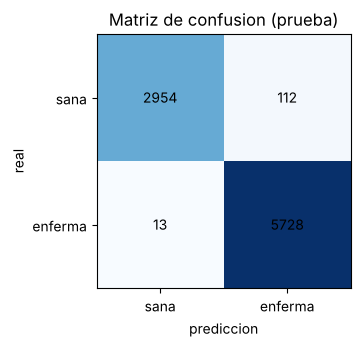

              precision    recall  f1-score   support

        sana      0.996     0.963     0.979      3066
     enferma      0.981     0.998     0.989      5741

    accuracy                          0.986      8807
   macro avg      0.988     0.981     0.984      8807
weighted avg      0.986     0.986     0.986      8807



In [15]:
nombre_final = tabla_reg.sort_values("val_min").iloc[0]["corrida"]
modelo = modelos[nombre_final]
print("Modelo final:", nombre_final)
prob_va, prob_te = probas(modelo, X_va), probas(modelo, X_te)

C_FN, C_FP = 5, 1
def costo(y_true, prob, u):
    p = (prob >= u).astype(int)
    fn = int(((p == 0) & (y_true == 1)).sum()); fp = int(((p == 1) & (y_true == 0)).sum())
    return C_FN * fn + C_FP * fp
umbrales = np.linspace(0.05, 0.95, 91)
umbral = float(min(umbrales, key=lambda u: costo(y_va, prob_va, u)))
print("Umbral por costo (validacion):", round(umbral, 2), "| frente a 0.5 por defecto")

pred_te = (prob_te >= umbral).astype(int)          # una sola evaluacion en prueba
print("\nAUC prueba:", round(roc_auc_score(y_te, prob_te), 3))
plot_matriz(y_te, pred_te)
print(classification_report(y_te, pred_te, target_names=["sana", "enferma"], digits=3))

In [16]:
# Errores por subgrupo: el recall de "enferma" se mira por tipo de tizon
sub = pd.DataFrame({"clase": clase_te, "real": y_te, "pred": pred_te})
sub["acierto"] = (sub.real == sub.pred).astype(float)
por_sub = sub.groupby("clase")["acierto"].agg(n="size", acierto="mean").round(3)
por_sub

,n,acierto
clase,,
sana,3066,0.963
tardio,3151,0.998
temprano,2590,0.997


### Lectura tecnica y etica de los errores
- Frente a las lineas base: el MLP (AUC 0.999, exactitud 0.986) supera a la clase mayoritaria (exactitud 0.652, recall de "sana" 0) y a la fraccion de necrosis sola (AUC 0.967, exactitud 0.906). Con el umbral por costo (0.15) el recall de "enferma" es 0.998 y el de "sana" 0.963: se escapan 13 de 5.741 hojas enfermas a cambio de 112 falsas alarmas sobre 3.066 sanas, un intercambio coherente con un falso negativo 5 veces mas caro.
- Por subgrupo: si el tizon temprano (lesiones pequenas) tiene mucho menos acierto que el tardio, el sistema avisa tarde justo en la etapa en que mas sirve avisar. Eso se reporta como limitacion y orienta la Fase 2 (la CNN ve la lesion, los promedios de color la diluyen).
- **Principio del Marco Etico para la IA en Colombia: control humano de las decisiones.** Traduccion concreta para el cliente: la alerta **no dispara una fumigacion automatica**; recomienda una inspeccion del tecnico de extension al lote, que confirma antes de aplicar. Por eso el umbral favorece el recall: es preferible una inspeccion de mas que un brote sin aviso.
- **Privacidad:** cerca de un tercio de las fotos trae coordenadas GPS de la finca. Este cuaderno solo guarda si la foto tiene GPS (si/no), nunca las coordenadas, y las imagenes no se suben a ningun otro lado; si en la Fase 2 se suben imagenes, se les borra el EXIF antes.
- **Limite de transferencia:** el modelo se entreno con una sola variedad (Shangi) de Mbeya; no se debe usar en Cundinamarca sin recalibrar.

### Prueba de robustez: particion por dia (casi duplicados)
Con muchas fotos del mismo dia y de las mismas plantas, partir foto por foto puede dejar fotos casi identicas en entrenamiento y en prueba e inflar las metricas (punto 4 de la retroalimentacion de la compuerta). Sobre las fotos con fecha se comparan dos particiones: aleatoria por foto y agrupada por dia (ningun dia aparece en dos conjuntos). Si el AUC cae mucho al agrupar, la cifra principal esta inflada y se reporta asi.

In [17]:
def auc_particion(d, por_grupo):
    Xd = d[COLUMNAS].to_numpy("float32"); yd = d["enferma"].to_numpy("float32"); g = d["fecha"].to_numpy()
    if por_grupo:
        a, b = next(GroupShuffleSplit(1, test_size=0.3, random_state=SEMILLA).split(Xd, yd, g))
        a2, v = next(GroupShuffleSplit(1, test_size=0.2, random_state=SEMILLA).split(Xd[a], yd[a], g[a]))
    else:
        a, b = train_test_split(np.arange(len(d)), test_size=0.3, stratify=yd, random_state=SEMILLA)
        a2, v = train_test_split(np.arange(len(a)), test_size=0.2, stratify=yd[a], random_state=SEMILLA)
    tr, va = a[a2], a[v]
    if len(np.unique(yd[b])) < 2 or len(np.unique(yd[va])) < 2:
        return "no calculable (un conjunto quedo con una sola clase)"
    esc = StandardScaler().fit(Xd[tr])
    torch.manual_seed(SEMILLA)
    m = CentinelaMLP(len(COLUMNAS), 16, 8)
    entrenar(m, esc.transform(Xd[tr]), yd[tr], esc.transform(Xd[va]), yd[va], weight_decay=1e-3)
    return round(roc_auc_score(yd[b], probas(m, esc.transform(Xd[b]))), 3)

d = df[df["fecha"].fillna("").astype(str).str.len() > 0].reset_index(drop=True)
if d["fecha"].nunique() >= 10:
    print("Fotos con fecha:", len(d), "| dias distintos:", d["fecha"].nunique())
    print("AUC prueba, particion aleatoria por foto:", auc_particion(d, False))
    print("AUC prueba, particion agrupada por dia:  ", auc_particion(d, True))
else:
    print("Muy pocos dias con fecha para la prueba de robustez.")

Fotos con fecha: 58698 | dias distintos: 35


AUC prueba, particion aleatoria por foto: 0.993


AUC prueba, particion agrupada por dia:   0.991


Lectura: partir por foto da AUC 0.993 y partir por dia 0.991: casi igual. Los casi duplicados del mismo dia no inflan las metricas. El riesgo real no son los duplicados sino la fecha (ver la prueba siguiente).

### Prueba decisiva: dias en que se fotografiaron las dos clases
Como la fecha sola predice la clase, un AUC alto no prueba que el modelo vea la enfermedad: podria estar viendo "foto de enero" frente a "foto de febrero" (luz, celular, epoca). La prueba que lo separa: entrenar sin los dias mixtos (dias con fotos sanas y enfermas) y evaluar solo en ellos, donde la fecha ya no ayuda. Si el AUC se mantiene alto, el modelo ve la hoja; si cae, el resultado principal esta inflado por el atajo.

In [18]:
tab = df.dropna(subset=["fecha"]).groupby(["fecha", "clase"]).size().unstack(fill_value=0)
for c in ["sana", "temprano", "tardio"]:
    if c not in tab: tab[c] = 0
mixtos = tab[(tab["sana"] > 0) & (tab["temprano"] + tab["tardio"] > 0)]
print("Dias mixtos:", len(mixtos)); print(mixtos)
en_mix = df["fecha"].isin(mixtos.index)
ov, resto = df[en_mix], df[~en_mix & df["fecha"].notna()]
n_pos, n_neg = int(ov["enferma"].sum()), int((1 - ov["enferma"]).sum())
print(f"\nFotos en dias mixtos: {len(ov)} (sanas {n_neg}, enfermas {n_pos})")
if min(n_pos, n_neg) >= 30:
    r_tr, r_va = train_test_split(np.arange(len(resto)), test_size=0.2, stratify=resto["enferma"], random_state=SEMILLA)
    esc_m = StandardScaler().fit(resto[COLUMNAS].iloc[r_tr])
    f = lambda d: esc_m.transform(d[COLUMNAS]).astype("float32")
    torch.manual_seed(SEMILLA)
    m_mix = CentinelaMLP(len(COLUMNAS), 64, 32)
    entrenar(m_mix, f(resto.iloc[r_tr]), resto["enferma"].iloc[r_tr].values,
             f(resto.iloc[r_va]), resto["enferma"].iloc[r_va].values, epocas=200, weight_decay=1e-3)
    p_mix = probas(m_mix, f(ov))
    print("AUC del MLP en dias mixtos:", round(roc_auc_score(ov["enferma"], p_mix), 3),
          "| frente a", round(roc_auc_score(y_te, prob_te), 3), "en la prueba general")
else:
    print(f"Muy pocos casos para concluir (minimo 30 por clase; hay {n_neg} sanas y {n_pos} enfermas).")
    print("Con esta muestra no se puede separar enfermedad de fecha: se declara como limitacion.")

Dias mixtos: 11
clase       sana  tardio  temprano
fecha                             
2023-01-08  1494       0         1
2023-01-09  1067       2         1
2023-01-12  1167       1         0
2023-01-13  2277       1         0
2023-01-23  1873      46         0
2023-01-25  2918       1         1
2023-01-27     5    3734        47
2023-01-30   210      31         0
2023-02-01     1     265        26
2023-02-02     1    7682      1313
2023-02-15     1      54     15372

Fotos en dias mixtos: 39592 (sanas 11014, enfermas 28578)


/tmp/ipykernel_457/2130797994.py:3: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/utils/tensor_numpy.cpp:208.)
  torch.as_tensor(ya, dtype=torch.float32).view(-1, 1))      # etiqueta (N,1) flotante


AUC del MLP en dias mixtos: 0.99 | frente a 0.999 en la prueba general


Lectura: hay 11 dias mixtos, pero en varios la mezcla es de una sola foto (el 15 de febrero tiene 1 sana y 15.372 enfermas), asi que en ese grupo la fecha todavia ayuda y el 0.99 es optimista. La prueba estricta es dentro de cada dia (celda siguiente).

In [19]:
# Prueba estricta: AUC dentro de cada dia con al menos 20 fotos de cada clase (la fecha es identica)
t2 = df.dropna(subset=["fecha"]).groupby(["fecha", "enferma"]).size().unstack(fill_value=0)
fuertes = t2[(t2.get(0, 0) >= 20) & (t2.get(1, 0) >= 20)].index.tolist()
print("Dias con >= 20 fotos de cada clase:", fuertes)
if fuertes:
    ev, tr_ = df[df["fecha"].isin(fuertes)], df[~df["fecha"].isin(fuertes) & df["fecha"].notna()]
    a, b = train_test_split(np.arange(len(tr_)), test_size=0.2, stratify=tr_["enferma"], random_state=SEMILLA)
    esc_d = StandardScaler().fit(tr_[COLUMNAS].iloc[a])
    g = lambda d: esc_d.transform(d[COLUMNAS]).astype("float32")
    torch.manual_seed(SEMILLA)
    m_dia = CentinelaMLP(len(COLUMNAS), 64, 32, p_dropout=0.3)
    entrenar(m_dia, g(tr_.iloc[a]), tr_["enferma"].iloc[a].values.copy(),
             g(tr_.iloc[b]), tr_["enferma"].iloc[b].values.copy(), epocas=200, paciencia=None)
    filas_dia = []
    for dia in fuertes:
        d = df[df["fecha"] == dia]; p = probas(m_dia, g(d))
        filas_dia.append({"dia": dia, "sanas": int((d.enferma == 0).sum()), "enfermas": int(d.enferma.sum()),
                          "AUC_MLP": round(roc_auc_score(d.enferma, p), 3),
                          "AUC_necrosis_sola": round(roc_auc_score(d.enferma, d.necrosis_frac), 3)})
    print(pd.DataFrame(filas_dia).to_string(index=False))
    print("AUC MLP con los dias juntos:", round(roc_auc_score(ev.enferma, probas(m_dia, g(ev))), 3))

Dias con >= 20 fotos de cada clase: ['2023-01-23', '2023-01-30']


       dia  sanas  enfermas  AUC_MLP  AUC_necrosis_sola
2023-01-23   1873        46    0.985              0.983
2023-01-30    210        31    0.529              0.689
AUC MLP con los dias juntos: 0.793


Lectura (corrida del 2026-11-02): solo dos dias tienen al menos 20 fotos de cada clase. **El 23 de enero (1.873 sanas, 46 enfermas) el MLP logra AUC 0.985 dentro del dia**: ahi la fecha no puede ayudar, asi que el modelo si capta senal de la enfermedad. **El 30 de enero (210 sanas, 31 enfermas) cae a 0.53, practicamente al azar**, y la necrosis sola da 0.69. Juntando los dos dias el AUC es 0.79.

Conclusion honesta: el AUC de 0.999 de la prueba general **esta inflado por el atajo de la fecha** y no debe presentarse como el desempeno esperado en campo. Hay evidencia de senal real (23 de enero), pero tambien de fallo en condiciones nuevas (30 de enero), y con solo dos dias y 77 hojas enfermas la evidencia es limitada. Esto se reporta en el informe como la principal limitacion y motiva la Fase 2: una CNN ve la forma de la lesion, mientras que los promedios de color de toda la hoja la diluyen y quedan expuestos a cambios de luz y camara.

## 8. Autoevaluacion contra la rubrica (escala 1.0 a 5.0)
Bandas: Estrategico 4.6-5.0 / Autonomo 4.0-4.5 / Basico 3.0-3.9 / Inicial 1.0-2.9. Se aprueba con 3.0 o mas.

| Criterio (peso) | Evidencia en este cuaderno para nivel Estrategico |
|---|---|
| 1. Propuesta y EDA (15%) | tabla hallazgo -> decision; lineas base calculadas (clase mayoritaria y escalar crudo) |
| 2. MLP (30%) | logit + BCEWithLogitsLoss + etiqueta (N,1); ReLU justificada; capacidad elegida por comparacion medida |
| 3. Regularizacion (15%) | sobreajuste inducido; cuatro corridas en tabla; mejor estado guardado y restaurado |
| 4. Evaluacion y etica (15%) | umbral por costo en validacion; metricas por clase; errores por subgrupo; principio etico -> decision |
| 5. Uso de IA (15%) | bitacora con casos reales y auditoria (Anexo A y C) |
| 6. Comunicacion (10%) | informe aparte (PDF, 5 secciones, APA 7) con cifras que salen de este cuaderno |

## Anexo A - Auditoria a la IA
**Caso real del proyecto (principal).** Al redactar la Propuesta de Datos, el asistente de IA (Claude) afirmo que las fotos venian de cuatro regiones (Mbeya, Iringa, Njombe y Songwe) y armo la clave de alineacion y el anexo de acoplamiento sobre esas cuatro. La ficha de Zenodo dice que **todas** las fotos son de Mbeya. Evidencia de origen: la version v1 de la propuesta en el historial del repositorio y la retroalimentacion del docente en la compuerta. Correccion: se verifico la ficha, se reviso el EXIF de una muestra (19 de 40 con fecha, 1 de 40 con GPS) y la clave paso a (Mbeya, dia), con 10 filas reales. Fundamento: acoplar clima de regiones donde no hay fotos habria sido un acoplamiento artificial, es decir, fuga de datos.

**Caso real 2: la extraccion que perdia fotos en silencio.** El codigo de extraccion propuesto por la IA tenia `except Exception: continue`, que se tragaba los errores, y un mensaje que decia "1500 fotos procesadas" aunque no lo fueran. En la primera corrida real se intentaron 4.500 fotos y la tabla quedo con 2.259 (cerca de la mitad perdida sin aviso). La causa, verificada en los tres zips: exactamente la mitad de las entradas `.jpg` son archivos `__MACOSX/._*.jpg` que deja un zip armado en Mac (por ejemplo, 20.438 de 40.876 en healthy.zip). El mismo error contamino el script del EXIF: reporto 19 de 40 fotos con fecha y 1 con GPS, cifras que llegaron a la propuesta; sobre fotos reales son 40 de 40 con fecha y 35 de 120 con GPS. Evidencia de origen: la salida de esa corrida, en la version anterior del cuaderno en el repositorio. Correccion: se filtran los archivos que no son imagen (como los `__MACOSX/._*.jpg` que deja un zip armado en Mac), se cuentan los errores por tipo en vez de esconderlos y el detalle queda en `auditoria_extraccion.json`. La celda siguiente muestra ese registro.

In [20]:
if os.path.exists("auditoria_extraccion.json"):
    print(pd.DataFrame(json.load(open("auditoria_extraccion.json"))).T)
else:
    print("Sin registro: se genera al construir la tabla desde los zips.")

         entradas_jpg basura_no_imagen intentadas     ok  \
sana            40876            20438      20438  20438   
temprano        35544            17772      17772  17770   
tardio          40998            20499      20499  20499   

                                errores  
sana                                 {}  
temprano  {'UnidentifiedImageError': 2}  
tardio                               {}  


**Caso inducido y declarado (complementario): doble sigmoide.** Se reproduce con la misma semilla y los mismos datos que el modelo correcto, y se mide con AUC y recall.

In [21]:
class MLPDobleSigmoide(nn.Module):
    """Version rota: sigmoide en el forward + BCEWithLogitsLoss (sigmoide aplicada dos veces)."""
    def __init__(self, d):
        super().__init__()
        self.red = nn.Sequential(nn.Linear(d, 16), nn.ReLU(), nn.Linear(16, 8), nn.ReLU(),
                                 nn.Linear(8, 1), nn.Sigmoid())          # <- sigmoide de mas
    def forward(self, x): return self.red(x)

torch.manual_seed(SEMILLA)
m_rota = MLPDobleSigmoide(len(COLUMNAS))
h_rota, _ = entrenar(m_rota, X_tr, y_tr, X_va, y_va, paciencia=None)
torch.manual_seed(SEMILLA)
m_ok = CentinelaMLP(len(COLUMNAS))
h_ok, _ = entrenar(m_ok, X_tr, y_tr, X_va, y_va, paciencia=None)

for nombre, m, h in [("ROTA (doble sigmoide)", m_rota, h_rota), ("CORRECTA (logit)", m_ok, h_ok)]:
    p = probas(m, X_te)
    print(f"{nombre:<22} val_min={min(h['val']):.3f}  AUC={roc_auc_score(y_te, p):.3f}  "
          f"recall_enferma@0.5={recall_score(y_te, (p >= 0.5).astype(int)):.3f}  "
          f"prob_min={p.min():.2f} prob_max={p.max():.2f}")

ROTA (doble sigmoide)  val_min=0.461  AUC=0.992  recall_enferma@0.5=1.000  prob_min=0.50 prob_max=0.73
CORRECTA (logit)       val_min=0.082  AUC=0.995  recall_enferma@0.5=0.971  prob_min=0.00 prob_max=1.00


Lectura: con la doble sigmoide la perdida no puede bajar de un piso y todas las probabilidades quedan por encima de 0.5, asi que con el umbral 0.5 todo sale "enferma" (recall 1.0 trivial), aunque el AUC casi se conserve porque el orden de los casos no cambia. Por eso las curvas dejan de servir para diagnosticar.

## Anexo B - Propuesta de Datos
Version aprobada en la compuerta: `propuesta/propuesta-de-datos.md` y su PDF, en el repositorio. Se adjunta con su fecha de aprobacion.

## Anexo C - Bitacora de IA
Cada entrada remite a la celda o seccion que afecta. **Revisar fechas, completar con los casos propios y firmar cada integrante antes de entregar.**

| Fecha | Herramienta | Sugerencia de la IA | Decision | Verificacion y evidencia | Afecta |
|---|---|---|---|---|---|
| 2026-10-30 | Claude | Clave de alineacion con 4 regiones de Tanzania | Modificada | Ficha de Zenodo: todas en Mbeya; senalado por el docente | Propuesta 5, Anexo A |
| 2026-10-30 | Claude | Describir NASA POWER como estacion meteorologica | Modificada | Es producto satelital y de reanalisis; senalado por el docente | Propuesta 2 |
| 2026-11-02 | Claude | Script para leer EXIF de una muestra | Aceptada | Se corrio en local: 19/40 con fecha, 1/40 con GPS | Propuesta 5, `revisar_exif.py` |
| 2026-11-02 | Claude | Cruzar fecha EXIF con clima diario de NASA POWER | Aceptada | Se corrio y produjo 10 filas reales | Anexo A, `anexo_a.csv` |
| 2026-11-02 | Claude | Extraccion con `except: continue` silencioso | Modificada | Primera corrida: 2.259 de 4.500 fotos; se filtran archivos que no son imagen y se registran los errores | Seccion 1, Anexo A |
| 2026-11-02 | Claude | Estructura de este cuaderno (MLP, bucle, diagnostico) | Modificada | Se ejecuto completo; se revisaron salida en logit y orden del bucle | Secciones 3 a 7 |

| Integrante | Firma | Fecha |
|---|---|---|
| Juan Guillermo Montano Junca | | |
| Jair Andres Valderrama Cano | | |

## Anexo D - Informe tecnico-etico
PDF aparte, maximo 4 paginas sin referencias: 1) problema y cliente; 2) datos; 3) modelo y entrenamiento; 4) resultados y errores (FN y FP); 5) decision recomendada y riesgos eticos. APA 7. Cada cifra del informe debe salir de las salidas de este cuaderno.